## Imports, paths, y funciones auxiliares

In [48]:
# Imports iniciales
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from collections import defaultdict

In [49]:
# Lo pongo así para que no se rompa el path
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

RAW_DIR = ROOT / "data" / "raw"
# Acepta "Totalizador_Formateado" y "Totalizadores_Formateados"
archivos = sorted(RAW_DIR.glob("Totalizador*_Formateado*.csv"))
assert archivos, f"No hay CSV en {RAW_DIR}: correr primero src/procesado_raw.py"

SEP = " | "                   # separador "Hoja | columna" que pone el procesado
ERRORES_EXCEL = ["#VALUE!", "#DIV/0!", "#N/A", "#REF!", "#NAME?", "#NUM!", "#NULL!"]
LIMITE = 23 * 3600            # 23:00:00 en segundos desde medianoche

SALIDA = ROOT / "data" / "processed" / "datos_base.csv"

In [50]:
def hoja_de(col):
    """'Consolidado EE | Frio (Kw)' -> 'Consolidado EE'. None para DIA, HORA"""
    return col.split(SEP, 1)[0] if SEP in col else None


def leer_formateado(ruta):
    # low_memory=False: con ~400 columnas de tipos mezclados pandas tipa por bloques
    df = pd.read_csv(ruta, low_memory=False, na_values=ERRORES_EXCEL,
                     dtype={"HORA": "string"})
    # El procesado escribe DIA como dd/mm/aaaa: sin format, pandas invierte día y mes
    df["DIA"] = pd.to_datetime(df["DIA"], format="%d/%m/%Y")
    return df

## Analisis inicial y Union
Primera parte del exploratorio, lo que quiero ver es como unir los 3 excels juntos y cuan mal están:

Los leo:

In [51]:
dfs = {}
for archivo in archivos:
    print("Leyendo", archivo.name)
    dfs[archivo.name] = leer_formateado(archivo)

for nombre, df in dfs.items():
    print(nombre, df.shape)

Leyendo Totalizador_Formateado 2020_2022.csv
Leyendo Totalizador_Formateado 2021_2023.csv
Leyendo Totalizador_Formateado 2022_2023.csv
Totalizador_Formateado 2020_2022.csv (15597, 343)
Totalizador_Formateado 2021_2023.csv (15318, 423)
Totalizador_Formateado 2022_2023.csv (12017, 430)


Parece que el primer excel tiene muchas menos columnas que los otros dos.

In [52]:
def a_segundos(horas):
    """Serie de horas en texto ('23:59:00') -> segundos desde las 00:00. NaN si no se entiende."""
    return pd.to_timedelta(horas, errors="coerce").dt.total_seconds()


def formato(seg):
    return f"{seg // 3600:02d}:{seg % 3600 // 60:02d}:{seg % 60:02d}"


def revisar_horas(df):
    """Horas posteriores a las 23:00:00 y valores de hora con formato raro."""
    horas = df["HORA"]
    segundos = a_segundos(horas)

    tarde = segundos[segundos > LIMITE]
    print("Horas > 23:00:00 (valor: cantidad de filas)")
    for seg, n in tarde.value_counts().sort_index().items():
        print(f"  {formato(int(seg))}: {n}")

    raros = horas[segundos.isna() & horas.notna()]
    if len(raros):
        print("Valores con formato no reconocido:")
        for valor, n in raros.astype(str).value_counts().items():
            print(f"  {valor!r}: {n}")

### Hoja Auxiliar

Al hacer una vista simple de los excels, vimos que hoja auxiliar no aporta nada, así que es lo primero que vamos a sacar.

In [53]:
# Auxiliar en los 3 archivos: % de nulos por columna, sobre todas las filas (no solo 23:59)
pct_aux = {}
for nombre, df in dfs.items():
    cols = [c for c in df.columns if hoja_de(c) == "Auxiliar"]
    pct_aux[nombre] = df[cols].isna().mean().mul(100).round(2)
    print(f"{nombre}: {len(cols)} columnas de Auxiliar | {len(df)} filas")

# Filas = columnas de Auxiliar, columnas = archivos.
# NaN en la tabla = esa columna no existe en ese archivo
tabla_aux = pd.DataFrame(pct_aux)
tabla_aux.index = tabla_aux.index.str.replace("Auxiliar | ", "", regex=False)
tabla_aux.columns = [c.replace("Totalizador_Formateado ", "").replace(".csv", "") for c in tabla_aux.columns]
tabla_aux

Totalizador_Formateado 2020_2022.csv: 32 columnas de Auxiliar | 15597 filas
Totalizador_Formateado 2021_2023.csv: 32 columnas de Auxiliar | 15318 filas
Totalizador_Formateado 2022_2023.csv: 33 columnas de Auxiliar | 12017 filas


,2020_2022,2021_2023,2022_2023
,0.15,0.01,100.0
.1,0.15,0.01,100.0
.10,100.00,100.00,100.0
.11,100.00,100.00,100.0
.12,100.00,100.00,100.0
.13,100.00,100.00,100.0
.14,100.00,100.00,100.0
.15,100.00,100.00,100.0
.16,100.00,100.00,100.0
.17,100.00,100.00,100.0


Está el porcentaje de nulos en cada columna. Existen algunas en las que se pueden encontrar valores, pero se ve que para el tercer excel es completamente nula, por lo tanto la sacamos.

In [54]:
# Saco todas las columnas de Auxiliar de los 3 archivos
for nombre, df in dfs.items():
    cols_aux = [c for c in df.columns if hoja_de(c) == "Auxiliar"]
    dfs[nombre] = df.drop(columns=cols_aux)
    print(f"{nombre}: saco {len(cols_aux)} columnas de Auxiliar -> {dfs[nombre].shape}")

Totalizador_Formateado 2020_2022.csv: saco 32 columnas de Auxiliar -> (15597, 311)
Totalizador_Formateado 2021_2023.csv: saco 32 columnas de Auxiliar -> (15318, 391)
Totalizador_Formateado 2022_2023.csv: saco 33 columnas de Auxiliar -> (12017, 397)


In [55]:
# Saco las filas que quedaron sin ningún dato (eran solo Auxiliar)
for nombre, df in dfs.items():
    cols = [c for c in df.columns if hoja_de(c) is not None] 
    vacias = df[cols].isna().all(axis=1)
    dfs[nombre] = df[~vacias].copy()
    print(f"{nombre}: saco {vacias.sum()} filas vacías -> {dfs[nombre].shape}")

Totalizador_Formateado 2020_2022.csv: saco 20 filas vacías -> (15577, 311)
Totalizador_Formateado 2021_2023.csv: saco 0 filas vacías -> (15318, 391)
Totalizador_Formateado 2022_2023.csv: saco 0 filas vacías -> (12017, 397)


### Análisis de días con más de 25 lecturas

In [56]:
# Cuántos días tienen N lecturas, por archivo: filas = N lecturas, columnas = archivo
dist_lecturas = pd.DataFrame({
    nombre.replace("Totalizador_Formateado ", "").replace(".csv", ""): df.groupby("DIA").size().value_counts()
    for nombre, df in dfs.items()
}).sort_index().fillna(0).astype(int)
dist_lecturas.index.name = "lecturas_por_dia"

dist_lecturas

,2020_2022,2021_2023,2022_2023
lecturas_por_dia,,,
8,1,0,1
9,0,1,0
16,0,1,1
17,0,0,1
20,0,0,1
23,2,3,1
24,5,3,0
25,594,585,459
26,2,1,4


Hay tres casos: 
- Tiene 25 valores, están bien (00:00 a 23:59).
- Tiene más de 25 valores. Si tiene 50/51, puede tenga dos días solapados. Idem. para 75 (no ocurre) o 100 (4 días juntos). 
- Tiene menos de 25 valores. Son días con pocas lecturas, que **no va a representar el consumo de esa jornada**.

Voy a arrancar por los días con más de 25 entradas. A los de 26 los voy a dejar como están por que seguramente sean valores duplicados y listo.
Para las columnas >26, lo que voy a hacer es si el 23:59 del bloque k tiene el mismo Frio que el del día DIA + k, el bloque es una copia y lo saco. Si es distinto, es otro día: va a DIA + k y las fechas que siguen se corren hasta el próximo día faltante.

In [57]:
MAX_FILAS = 26
FRIO = "Consolidado EE | Frio (Kw)"
INICIO_2359 = 23 * 3600 + 59 * 60

for nombre, df in dfs.items():
    conteo = df.groupby("DIA").size()
    es_pegado = df["DIA"].isin(conteo[conteo > MAX_FILAS].index)

    # 1. Bloques: corto cuando la hora vuelve para atrás y arranca en 00:xx (día nuevo).
    #    Las filas sueltas del final del día (partidas) no abren un bloque.
    seg = a_segundos(df["HORA"])
    corte = (seg.groupby(df["DIA"]).diff() < 0) & (seg < 3600) & es_pegado
    bloque = corte.groupby(df["DIA"]).cumsum()

    # 2. Desempate: Frio de las 23:59 de cada bloque contra el del día DIA + bloque
    tmp = pd.DataFrame({"DIA": df["DIA"], "bloque": bloque, "frio": df[FRIO]})
    cierre = (tmp[seg.between(INICIO_2359, INICIO_2359 + 59)]
              .groupby(["DIA", "bloque"])["frio"].first().reset_index())
    base = cierre[cierre["bloque"] == 0].set_index("DIA")["frio"]
    extra = cierre[cierre["bloque"] > 0].reset_index(drop=True)
    frio_siguiente = base.reindex(extra["DIA"] + pd.to_timedelta(extra["bloque"], unit="D")).reset_index(drop=True)
    copias = extra[(extra["frio"] - frio_siguiente).abs() < 1e-6]
    copias = set(zip(copias["DIA"], copias["bloque"]))

    claves = list(zip(df["DIA"], bloque))
    queda = [k not in copias for k in claves]
    df = df[queda].copy()
    claves = [k for k, q in zip(claves, queda) if q]

    # 3. Fechas: recorro los (DIA, bloque) en orden. Cada uno va a su DIA, o al día siguiente
    #    del anterior si ese ya está ocupado. Los días faltantes (31, 29-31/08) absorben el corrimiento.
    nueva_fecha, ultima = {}, None
    for dia, b in sorted(set(claves)):
        ultima = dia if ultima is None else max(dia, ultima + pd.Timedelta(days=1))
        nueva_fecha[(dia, b)] = ultima
    df["DIA"] = [nueva_fecha[k] for k in claves]
    dfs[nombre] = df


In [58]:

# Los archivos que arrancan el 01/07 no conocen el corrimiento que traía el archivo anterior:
# julio y agosto de su primer año se toman del archivo anterior
for i, nombre in enumerate(dfs):
    if i == 0:
        continue
    df = dfs[nombre]
    inicio = pd.Timestamp(year=df["DIA"].min().year, month=9, day=1)
    dfs[nombre] = df[df["DIA"] >= inicio].copy()

Despues de tratar a los días >26, me voy con los 21<. Directamente los voy a borrar, por que no acumulan datos. Dejo los de 23/24 por que un único valor faltante no influya tanto seguramente.


In [59]:
# Saco los días con menos de 20 lecturas
MIN_LECTURAS = 20
for nombre, df in dfs.items():
    lecturas = df.groupby("DIA")["DIA"].transform("size")
    dfs[nombre] = df[lecturas >= MIN_LECTURAS].copy()
    print(f"{nombre}: saco {(lecturas < MIN_LECTURAS).sum()} filas -> {dfs[nombre].shape}")

Totalizador_Formateado 2020_2022.csv: saco 8 filas -> (15569, 311)
Totalizador_Formateado 2021_2023.csv: saco 25 filas -> (13822, 391)
Totalizador_Formateado 2022_2023.csv: saco 41 filas -> (10501, 397)


### Filtrado Por Hora

Elegimos las 23:59 en vez de las 23:00 por que si no se estaría perdiendo una hora de producción (hay una hora de diferencia entre 23:00 y 00:00 que registra las :59).
Me ponga a ver como es el formato de las :59 

In [60]:
for nombre, df in dfs.items():
    print(f"\n=== {nombre} ===")
    revisar_horas(df)


=== Totalizador_Formateado 2020_2022.csv ===
Horas > 23:00:00 (valor: cantidad de filas)
  23:00:01: 10
  23:59:00: 614
  23:59:01: 7
  23:59:59: 1

=== Totalizador_Formateado 2021_2023.csv ===
Horas > 23:00:00 (valor: cantidad de filas)
  23:00:01: 5
  23:59:00: 548
  23:59:01: 4
  23:59:59: 1

=== Totalizador_Formateado 2022_2023.csv ===
Horas > 23:00:00 (valor: cantidad de filas)
  23:00:01: 4
  23:59:00: 416
  23:59:01: 3
  23:59:59: 1


In [61]:
def filtrar_2359(df):
    """Deja solo las filas con hora 23:59:xx (23:59:00, 23:59:01, 23:59:59)."""
    seg = a_segundos(df["HORA"].astype("string"))
    inicio = 23 * 3600 + 59 * 60          # 23:59:00
    fin = inicio + 59                     # 23:59:59
    return df[(seg >= inicio) & (seg <= fin)].copy()

Saco ahora todos los valores que no sean 
- 23:59:00
- 23:59:01
- 23:59:59

In [62]:
# Me quedo solo con la lectura de cierre (23:59:00, 23:59:01, 23:59:59)
for nombre, df in dfs.items():
    dfs[nombre] = filtrar_2359(df)
    print(f"{nombre}: {len(dfs[nombre])} filas 23:59 | {dfs[nombre]['DIA'].nunique()} días")

Totalizador_Formateado 2020_2022.csv: 622 filas 23:59 | 621 días
Totalizador_Formateado 2021_2023.csv: 553 filas 23:59 | 551 días
Totalizador_Formateado 2022_2023.csv: 420 filas 23:59 | 418 días


Ahora, con los datos juntados, uno todas las hojas de los archivos. Primero reviso que todos tengan las mismas hojas:

In [63]:
# Hojas de cada archivo y cuáles le faltan respecto del total
hojas_por_archivo = {n: {hoja_de(c) for c in df.columns} - {None} for n, df in dfs.items()}
todas = set.union(*hojas_por_archivo.values())
for n, h in hojas_por_archivo.items():
    print(f"{n}: {len(h)} hojas | faltan: {sorted(todas - h)}")


Totalizador_Formateado 2020_2022.csv: 14 hojas | faltan: ['Seguimiento Dia']
Totalizador_Formateado 2021_2023.csv: 15 hojas | faltan: []
Totalizador_Formateado 2022_2023.csv: 14 hojas | faltan: ['Seguimiento Dia']


Borro seguimiento día por que está en solo un excel:

In [64]:
# Seguimiento Dia está solo en 2021_2023: la saco de todos
HOJAS_DESCARTAR = ["Seguimiento Dia"]
for n, df in dfs.items():
    cols = [c for c in df.columns if hoja_de(c) in HOJAS_DESCARTAR]
    dfs[n] = df.drop(columns=cols)
    print(f"{n}: saco {len(cols)} columnas de {HOJAS_DESCARTAR}")

Totalizador_Formateado 2020_2022.csv: saco 0 columnas de ['Seguimiento Dia']
Totalizador_Formateado 2021_2023.csv: saco 3 columnas de ['Seguimiento Dia']
Totalizador_Formateado 2022_2023.csv: saco 0 columnas de ['Seguimiento Dia']


### Análisis de tipo de dato

In [65]:
# Tipos de dato por archivo: cuántas columnas hay de cada tipo
tipos = pd.DataFrame({
    nombre.replace("Totalizador_Formateado ", "").replace(".csv", ""): df.dtypes.astype(str).value_counts()
    for nombre, df in dfs.items()
}).fillna(0).astype(int)
print(tipos, "\n")

# Columnas que no son numéricas ni fecha, por archivo
for nombre, df in dfs.items():
    print(f"{nombre}: {df.select_dtypes(exclude=['number', 'datetime']).columns.tolist()}")

                2020_2022  2021_2023  2022_2023
datetime64[us]          1          1          1
float64               302        385        394
str                     7          1          1
string                  1          1          1 

Totalizador_Formateado 2020_2022.csv: ['HORA', 'Totalizadores Produccion | Nivel Silo Bagazo Norte (1)', 'Totalizadores Energia | KW Trafo 8', 'Totalizadores Efluentes | Totalizador Bba P1', 'Totalizadores Efluentes | Totalizador Bba P2', 'Totalizadores Efluentes | Totalizador Bba P4', 'Totalizadores Efluentes | Totalizador Bba Envasado', 'Totalizadores Efluentes | Totalizador Bba P51']
Totalizador_Formateado 2021_2023.csv: ['HORA', 'Totalizadores Energia | KW Trafo 8']
Totalizador_Formateado 2022_2023.csv: ['HORA', 'Consolidado KPI | Unnamed: 124']


In [66]:
def a_float(serie):
    if pd.api.types.is_numeric_dtype(serie):
        return serie.astype("float64")
    txt = serie.astype("string").str.strip()
    # punto de miles: hay 2 o más puntos, o hay punto y coma a la vez
    miles = (txt.str.count(r"\.").ge(2) | (txt.str.contains(".", regex=False) & txt.str.contains(",", regex=False))).fillna(False)
    txt = txt.mask(miles, txt.str.replace(".", "", regex=False))
    return pd.to_numeric(txt.str.replace(",", ".", regex=False), errors="coerce").astype("float64")

NO_CONVERTIR = ["DIA", "HORA"]
for nombre, df in dfs.items():
    cols = df.columns.drop(NO_CONVERTIR, errors="ignore")
    df[cols] = df[cols].apply(a_float)
    dfs[nombre] = df
    print(f"{nombre}: {df.dtypes.astype(str).value_counts().to_dict()}")

Totalizador_Formateado 2020_2022.csv: {'float64': 309, 'datetime64[us]': 1, 'string': 1}
Totalizador_Formateado 2021_2023.csv: {'float64': 386, 'datetime64[us]': 1, 'string': 1}
Totalizador_Formateado 2022_2023.csv: {'float64': 395, 'datetime64[us]': 1, 'string': 1}


### Union de los datos

In [67]:
# Uno los 3 archivos (ya filtrados a 23:59)
partes = []
for nombre, df in dfs.items():
    f = df.copy()
    f.insert(0, "ARCHIVO", nombre.replace("Totalizador_Formateado ", "").replace(".csv", ""))
    partes.append(f)

df_total = pd.concat(partes, ignore_index=True).sort_values(["DIA", "HORA"], kind="stable").reset_index(drop=True)
print(df_total.shape, df_total["DIA"].min().date(), "->", df_total["DIA"].max().date())

(1595, 412) 2020-07-01 -> 2023-10-27


# Analisis del DF completo

Para ver la cantidad de días únicos: 

In [68]:
# Días únicos en el df unido, y cuántos aparecen repetidos
por_dia = df_total.groupby("DIA").agg(filas=("ARCHIVO", "size"), archivos=("ARCHIVO", "nunique"))
print("Días únicos:", len(por_dia))
print("Días con más de una fila:", (por_dia["filas"] > 1).sum())
print("Días presentes en más de un archivo:", (por_dia["archivos"] > 1).sum())
print("Días repetidos dentro de un mismo archivo:", df_total.groupby(["ARCHIVO", "DIA"]).size().gt(1).sum())

Días únicos: 1205
Días con más de una fila: 388
Días presentes en más de un archivo: 385
Días repetidos dentro de un mismo archivo: 5


In [69]:
df_total = df_total.drop(columns=["HORA", "ARCHIVO"])

## Tratamiento de los unnameds 

Al ver el dataset, encontramos muchas columnas llamadas unnamed (numero). Puede que haya alguna que tenga valores de verdad, y otras que simplemente son errores. Para descartar los errores, vamos a hacer un df aparte con los unnameds y analizar el porcentaje de nulos:

In [70]:
# Columnas unnamed (vienen como "Hoja | Unnamed: N")
cols_unnamed = [c for c in df_total.columns if "Unnamed" in c]

unnamed = pd.DataFrame({
    "hoja": [hoja_de(c) for c in cols_unnamed],
    "nulos": df_total[cols_unnamed].isna().sum(),
}, index=cols_unnamed)

unnamed["pct_nulos"] = (unnamed["nulos"] / len(df_total) * 100).round(2)
unnamed = unnamed.sort_values("pct_nulos")

print(f"{len(unnamed)} columnas unnamed")
unnamed

24 columnas unnamed


,hoja,nulos,pct_nulos
Consolidado Produccion | Unnamed: 15,Consolidado Produccion,1552,97.30
Consolidado Produccion | Unnamed: 16,Consolidado Produccion,1552,97.30
Consolidado Produccion | Unnamed: 17,Consolidado Produccion,1552,97.30
Consolidado Produccion | Unnamed: 18,Consolidado Produccion,1552,97.30
Totalizadores Energia | Unnamed: 53,Totalizadores Energia,1564,98.06
Totalizadores Energia | Unnamed: 54,Totalizadores Energia,1594,99.94
Totalizadores Energia | Unnamed: 56,Totalizadores Energia,1594,99.94
Totalizadores Energia | Unnamed: 55,Totalizadores Energia,1594,99.94
Totalizadores Energia | Unnamed: 57,Totalizadores Energia,1594,99.94
Totalizadores Energia | Unnamed: 58,Totalizadores Energia,1594,99.94


In [71]:
df_recortado = df_total.drop(columns=unnamed.index)
print(f"Saco {len(unnamed)} columnas unnamed -> {df_recortado.shape}")

Saco 24 columnas unnamed -> (1595, 386)


## Tratado de duplicados y regla de desempate

Vamos a tomar como criterio de desempate: 
- Nos quedamos con la fila con mayor cantidad de valores nulos, y en caso que la fila descartada tenga algún valor real que para la fila guardada es nula, se va a rellenar. 

In [72]:
# Días que aparecen en más de una fila (se cuenta la clave DIA, no las filas)
df_dup = df_recortado.copy()
dias_repetidos = df_dup.loc[df_dup["DIA"].duplicated(keep=False), "DIA"].drop_duplicates()

print("Total de días repetidos:", len(dias_repetidos), "\n")
#print(df_dup[df_dup["DIA"].duplicated() == True])


Total de días repetidos: 388 



In [73]:
cols_datos = df_dup.columns.drop("DIA")

# Cantidad de nulos de cada fila; _orden guarda el orden original para el desempate
df_dup["_nulos"] = df_dup[cols_datos].isna().sum(axis=1)        
df_dup["_orden"] = range(len(df_dup))   

# Dentro de cada día: primero la fila con menos nulos; si empatan, la que venía primero
ordenado = df_dup.sort_values(["DIA", "_nulos", "_orden"])

print(ordenado[["DIA", "_nulos", "_orden"]].head(10))
# first() toma, por columna, el primer valor no nulo del grupo:
# la fila base conserva sus valores y sus huecos se rellenan con las siguientes
df_unido = ordenado.groupby("DIA", sort=True)[list(cols_datos)].first().reset_index()

assert df_unido["DIA"].is_unique
assert len(df_unido) == df_dup["DIA"].nunique()

         DIA  _nulos  _orden
0 2020-07-01      91       0
1 2020-07-02      91       1
2 2020-07-03      91       2
3 2020-07-04      91       3
4 2020-07-05      91       4
5 2020-07-06      91       5
6 2020-07-07      91       6
7 2020-07-08      91       7
8 2020-07-09      91       8
9 2020-07-10      91       9


In [74]:
df_unido.info()

<class 'pandas.DataFrame'>
RangeIndex: 1205 entries, 0 to 1204
Columns: 386 entries, DIA to Totalizadores Glicol | Tot L3, L4 y Planta de CO2
dtypes: datetime64[us](1), float64(385)
memory usage: 3.5 MB


El info indica que tiene 1185 entradas.

In [75]:
print("Dia mas viejo:", df_unido["DIA"].min().date())
print("Dia mas nuevo:", df_unido["DIA"].max().date())
tot_dias = df_unido["DIA"].nunique()
print("Cantidad de días/filas en el dataset:", tot_dias)

diferencia = df_unido["DIA"].max() - df_unido["DIA"].min()
print("Diferencia en dias segun rango min-max:", diferencia.days)

Dia mas viejo: 2020-07-01
Dia mas nuevo: 2023-10-27
Cantidad de días/filas en el dataset: 1205
Diferencia en dias segun rango min-max: 1213


No quedan tantos días restantes, seguramente sean los que tenian pocos valores en los días.

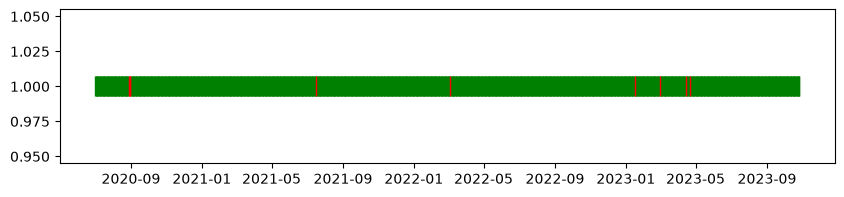

In [76]:
rango = pd.date_range(start=df_unido['DIA'].min(), end=df_unido['DIA'].max(), freq='D')

# 3. Ver cuáles faltan
faltantes = rango.difference(df_unido['DIA'].dt.normalize())

# 4. Graficar de forma simple
plt.figure(figsize=(10, 2))
plt.plot(df_unido['DIA'], [1] * len(df_unido), '|', color='green', markersize=15, label='Días con datos')
plt.plot(faltantes, [1] * len(faltantes), '|', color='red', markersize=15, label='Días faltantes')

plt.show()


In [77]:
print(len(faltantes))
print("Dia menor: ", df_unido['DIA'].min().date(), " Dia mayor: ", df_unido['DIA'].max().date())
print("Días faltantes en el dataset segun rango min-max: \n", faltantes.date)

9
Dia menor:  2020-07-01  Dia mayor:  2023-10-27
Días faltantes en el dataset segun rango min-max: 
 [datetime.date(2020, 8, 29) datetime.date(2020, 8, 30)
 datetime.date(2020, 8, 31) datetime.date(2021, 7, 16)
 datetime.date(2022, 3, 5) datetime.date(2023, 1, 17)
 datetime.date(2023, 2, 28) datetime.date(2023, 4, 15)
 datetime.date(2023, 4, 21)]


## Ciclico dias y estacion


In [78]:
df_unido["DIA_SEMANA"] = (df_unido["DIA"] + pd.Timedelta(days=1)).dt.dayofweek 

df_unido["DS_sin"] = np.sin(2 * np.pi * df_unido["DIA_SEMANA"] / 7)
df_unido["DS_cos"] = np.cos(2 * np.pi * df_unido["DIA_SEMANA"] / 7)

# DIA_SEMANA SERIA EL QUE INDICA LO CICLICO
# Esta codificacion permite tomar 0 = Lunes = dia que intenta predecir esa fila
# 0= Lunes, 1=Martes, 2=Miércoles, 3=Jueves, 4=Viernes, 5=Sábado, 6=Domingo

df_unido[["DIA", "DIA_SEMANA", "DS_sin", "DS_cos"]].head(5)

C:\Users\Usuario\AppData\Local\Temp\ipykernel_16760\3142354343.py:1: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df_unido["DIA_SEMANA"] = (df_unido["DIA"] + pd.Timedelta(days=1)).dt.dayofweek


,DIA,DIA_SEMANA,DS_sin,DS_cos
0,2020-07-01,3,0.433884,-0.900969
1,2020-07-02,4,-0.433884,-0.900969
2,2020-07-03,5,-0.974928,-0.222521
3,2020-07-04,6,-0.781831,0.623490
4,2020-07-05,0,0.000000,1.000000


Dado la tematica que estamos tratando, tambien quiero ver la ciclicidad entre meses/estaciones, es logico que el consumo sea mayor en verano y por ende tambien la produccion

En total se creo, el MES, su ciclicidad (sen-cos) y ESTACION, Ademas de DIA
Tambien codifico segun el hemisferio en el que me encuentro (NORTE), tal que queda  0 = "invierno", 1 = "primavera", 2 ="verano", 3 = "otoño"



In [79]:
df_dias = df_unido.copy()
df_dias["MES"] = df_dias["DIA"].dt.month
df_dias["DIA_ANIO"] = df_dias["DIA"].dt.dayofyear

df_dias["ANIO_sin"] = np.sin(2 * np.pi * df_dias["DIA_ANIO"] / 365.25)
df_dias["ANIO_cos"] = np.cos(2 * np.pi * df_dias["DIA_ANIO"] / 365.25)

# Estaciones meteorológicas, hemisferio norte
estacion = {12: "invierno", 1: "invierno", 2: "invierno",
            3: "primavera", 4: "primavera", 5: "primavera",
            6: "verano", 7: "verano", 8: "verano",
            9: "otoño", 10: "otoño", 11: "otoño"}
df_dias["ESTACION"] = df_dias["MES"].map(estacion)


C:\Users\Usuario\AppData\Local\Temp\ipykernel_16760\1134665939.py:3: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  df_dias["DIA_ANIO"] = df_dias["DIA"].dt.dayofyear


Como estamos tratando sobre el hemisferio norte, quiero que 

In [80]:
df_dias[["DIA", "MES", "ESTACION"]].head(5)


,DIA,MES,ESTACION
0,2020-07-01,7,verano
1,2020-07-02,7,verano
2,2020-07-03,7,verano
3,2020-07-04,7,verano
4,2020-07-05,7,verano


In [81]:
df_dias.columns

Index(['DIA', 'Consolidado KPI | EE Planta / Hl',
       'Consolidado KPI | EE Elaboracion / Hl',
       'Consolidado KPI | EE Bodega / Hl', 'Consolidado KPI | EE Cocina / Hl',
       'Consolidado KPI | EE Envasado / Hl',
       'Consolidado KPI | EE Linea 2 / Hl',
       'Consolidado KPI | EE Linea 3 / Hl',
       'Consolidado KPI | EE Linea 4 / Hl',
       'Consolidado KPI | EE Linea 5 / Hl',
       ...
       'Totalizadores Efluentes | Id',
       'Totalizadores Glicol | Tot L3, L4 y Planta de CO2', 'DIA_SEMANA',
       'DS_sin', 'DS_cos', 'MES', 'DIA_ANIO', 'ANIO_sin', 'ANIO_cos',
       'ESTACION'],
      dtype='str', length=394)

Relleno los que quedan con un promedio de 2 días anteriores y 2 posteriores para que funcionen bien las series cronologicas

In [82]:
# Días faltantes: los relleno con el promedio de los 2 días anteriores y los 2 posteriores
df_unido = df_unido.set_index("DIA").reindex(rango).rename_axis("DIA")
vecinos = pd.concat([df_unido.shift(k) for k in (2, 1, -1, -2)])
promedio = vecinos.groupby(level=0).mean(numeric_only=True)
df_unido.loc[faltantes] = promedio.loc[faltantes]
df_unido = df_unido.reset_index()
print(f"Relleno {len(faltantes)} días -> {df_unido.shape}")

Relleno 9 días -> (1214, 389)


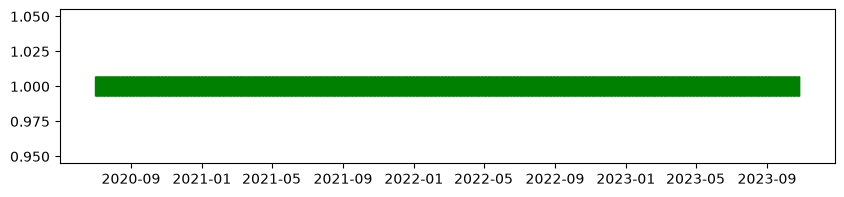

In [83]:
rango = pd.date_range(start=df_unido['DIA'].min(), end=df_unido['DIA'].max(), freq='D')
faltantes = rango.difference(df_unido['DIA'].dt.normalize())

plt.figure(figsize=(10, 2))
plt.plot(df_unido['DIA'], [1] * len(df_unido), '|', color='green', markersize=15, label='Días con datos')
plt.plot(faltantes, [1] * len(faltantes), '|', color='red', markersize=15, label='Días faltantes')

plt.show()

## Crear la Label

In [84]:
# Variable objetivo: Frio (Kw) del día siguiente (D+1), alineado con las features del día D
df_unido = df_unido.sort_values("DIA").reset_index(drop=True)

# Frio viene definido de arriba como la columna de frio en KW
df_unido["target"] = df_unido[FRIO].shift(-1)

# Saco el último dia:
df_unido = df_unido.dropna(subset=["target"]).reset_index(drop=True)

print(df_unido[["DIA", FRIO, "target"]].head())
print(df_unido.shape)

         DIA  Consolidado EE | Frio (Kw)   target
0 2020-07-01                     14325.0  23954.0
1 2020-07-02                     23954.0  28268.0
2 2020-07-03                     28268.0  24246.0
3 2020-07-04                     24246.0  29885.0
4 2020-07-05                     29885.0  24449.0
(1213, 390)


In [85]:
# Guardo el dataset final del EDA: 1 fila por día, con target
SALIDA.parent.mkdir(parents=True, exist_ok=True)
df_unido.to_csv(SALIDA, index=False, date_format="%Y-%m-%d")
print("Guardado en", SALIDA, df_unido.shape)

Guardado en c:\Users\Usuario\Cerveceria-LabDatosII\data\processed\datos_base.csv (1213, 390)


---
---
---
---
---
---
---
---
---
---
---
---

## CAMBIAR!!

In [86]:

# Si df_total tiene columnas MultiIndex (hoja, columna), las aplano a solo el nombre
if isinstance(df_total.columns, pd.MultiIndex):
    df_total.columns = df_total.columns.get_level_values(-1)

# Solo numéricas y con variación (las constantes dan falsos positivos)
X = df_total.select_dtypes("number")
X = X.loc[:, (X.nunique() > 1).values]
X = X.loc[:, ~X.columns.astype(str).str.startswith("Unnamed")]

# Etiqueta única por columna: "nombre [posición]"
X.columns = [f"{c} [{i}]" for i, c in enumerate(X.columns)]
print(X.shape)

(1595, 367)


In [87]:
base = pd.Series(X.columns).str.replace(r"\s*\[\d+\]$", "", regex=True).str.lower().str.strip()
rep = base[base.duplicated(keep=False)]
print(rep.groupby(rep).apply(lambda s: list(X.columns[s.index])).to_string())

Series([], )


In [88]:
grupos = defaultdict(list)
for col in X.columns:
    h = pd.util.hash_pandas_object(X[col].round(4), index=False).sum()
    grupos[h].append(col)

identicas = [cols for cols in grupos.values() if len(cols) > 1]
for cols in identicas:
    print(cols)
print(f"\n{len(identicas)} grupos de columnas idénticas")

['Consolidado Produccion | Hl Cerveza L2 [59]', 'Totalizadores Produccion | Hl Cerveza L2 [84]']
['Consolidado Produccion | Hl Cerveza L3 [60]', 'Totalizadores Produccion | Hl Cerveza L3 [85]']
['Consolidado Produccion | Hl Cerveza L4 [61]', 'Totalizadores Produccion | Hl Cerveza L4 [86]']
['Consolidado Produccion | Hl Cerveza L5 [62]', 'Totalizadores Produccion | Hl Cerveza L5 [87]']
['Consolidado Produccion | Cocimientos Diarios [63]', 'Totalizadores Produccion | Cocimientos Diarios [88]']
['Consolidado EE | KW Gral Planta [110]', 'Totalizadores Energia | KW Gral Planta [111]']
['Consolidado Agua | Red L1 y L2 [169]', 'Totalizadores Agua | Red L1 y L2 [176]']
['Consolidado Agua | FC L1 y L2 [170]', 'Totalizadores Agua | FC L1 y L2 [177]']
['Consolidado Agua | FC Lavadora L2 [171]', 'Totalizadores Agua | FC Lavadora L2 [202]']
['Consolidado Agua | Red L3 [172]', 'Totalizadores Agua | Red L3 [179]']
['Consolidado Agua | FC Lavadora L3 [173]', 'Totalizadores Agua | FC Lavadora L3 [200]'

In [89]:
corr = X.corr()
mask = np.triu(np.ones(corr.shape, dtype=bool), k=1)
pares = corr.where(mask).stack().reset_index()
pares.columns = ["a", "b", "r"]

umbral = 0.999                         # bajalo a 0.98 para ver las "demasiado parecidas"
pares = pares[pares["r"].abs() > umbral].sort_values("r", ascending=False)
print(len(pares), "pares con |r| >", umbral)
print(pares.to_string(index=False))

584 pares con |r| > 0.999
                                                   a                                                         b         r
                       Totalizadores Aire | Id [363]                        Totalizadores Efluentes | Id [365]  1.000000
                Totalizadores Gas y Vapor | Id [362]                        Totalizadores Efluentes | Id [365]  1.000000
                Totalizadores Gas y Vapor | Id [362]                             Totalizadores Aire | Id [363]  1.000000
          Consolidado GasVapor | Vapor_L5 (KG) [346]           Totalizadores Gas y Vapor | Vapor_L5 (KG) [350]  1.000000
                Consolidado KPI | Meta Aire L5 [336]               Consolidado KPI | Meta Aire Servicios [337]  1.000000
                Consolidado KPI | Meta Aire L4 [335]               Consolidado KPI | Meta Aire Servicios [337]  1.000000
                Consolidado KPI | Meta Aire L3 [334]                      Consolidado KPI | Meta Aire L5 [336]  1.000000
      